# 02 · Model and clustering: from alarm pairs to incidents

[Notebook 01](01_data_and_labels.ipynb) showed that no single signal is a label. This notebook follows the method that
works around it, on the held-out test days:

1. **Candidate graph**: which alarm pairs are even worth scoring.
2. **Pair model**: a GATv2 network scores each candidate pair, trained on weak co-clear labels.
3. **Clustering**: average linkage with mutual best, then tickets join clusters into incidents.
4. **Where it still fails**: errors by kind of incident.

The pipeline itself is `python -m aig.run` ([`src/aig/run.py`](../src/aig/run.py)). This notebook reuses its output in
`runs/demo` and runs it first if needed. As before, ground truth is used **only to evaluate**; the threshold was
chosen on the validation days from resolution codes alone.

In [1]:
import sys, json, subprocess
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from aig import cluster
from aig.data import load_corpus, day_nodes, day_tickets
from aig.graph import build_day, EDGE_FEATURES, HOPS
from aig.model import DayTensors, PairGNN, Vocab, score
from aig.evaluate import ticket_homes
from aig.run import group_day, main as run_pipeline

DATA, RUN, FIG = ROOT / "data" / "synthetic", ROOT / "runs" / "demo", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
if not (DATA / "alarms.csv").exists():
    subprocess.run([sys.executable, str(ROOT / "synthetic" / "generate.py"), "--days", "14", "--out", str(DATA)], check=True)
if not (RUN / "results.csv").exists():
    run_pipeline(["--data", str(DATA), "--out", str(RUN), "--train-days", "8", "--val-days", "2"])

BLUE, ORANGE, AQUA, YELLOW, OTHER = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c3c2b7"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e3"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "lines.linewidth": 2, "legend.frameon": False,
})

c = load_corpus(DATA)
ckpt = torch.load(RUN / "model.pt", weights_only=False)
vocab = Vocab.__new__(Vocab)
vocab.__dict__.update(ckpt["vocab"])
model = PairGNN(*vocab.sizes(), n_num=3, e_dim=len(EDGE_FEATURES))
model.load_state_dict(ckpt["state"])
THR = ckpt["threshold"]
run = json.loads((RUN / "run.json").read_text())
kind_of = pd.read_csv(DATA / "truth" / "incidents.csv").set_index("incident_id").kind
truth = c.truth.set_index("alarm_id").incident_id

def load_day(d):
    n = day_nodes(c, d)
    nt, E = day_tickets(c, n), build_day(n, c.links)
    inc_id = n.alarm_id.map(truth).to_numpy()
    true, uniq = pd.factorize(inc_id)
    return dict(n=n, nt=nt, E=E, s=score(model, DayTensors(n, E, vocab)), inc_id=inc_id, true=true, uniq=np.asarray(uniq))

days = {pd.Timestamp(d): load_day(pd.Timestamp(d)) for d in run["test"]}
print(f"train {run['train'][0]} .. {run['train'][-1]}, validation {', '.join(run['val'])}, "
      f"test {', '.join(run['test'])}; threshold {THR:.2f}")
print(f"test days: {sum(len(v['n']) for v in days.values()):,} alarms, "
      f"{sum(len(v['E']['i']) for v in days.values()):,} candidate pairs")

train 2026-01-05 .. 2026-01-12, validation 2026-01-13, 2026-01-14, test 2026-01-15, 2026-01-16, 2026-01-17, 2026-01-18; threshold 0.10
test days: 11,114 alarms, 100,232 candidate pairs


## 1 · The candidate graph

Scoring every pair of a day's alarms is out of reach (a real day has hundreds of thousands of alarms). The graph proposes
candidates from four sources and leaves the decision to the model. Each source catches pairs the others miss: the
topology reaches linked sites tens of kilometres apart, and the one-site source reaches an hour back, to the mains failure
that drained the battery.

In [2]:
rows = []
for v in days.values():
    E = v["E"]
    same = v["inc_id"][E["i"]] == v["inc_id"][E["j"]]
    for bit, name in [(1, "near in time and space"), (2, "no site, same domain"),
                      (4, "linked in the topology"), (8, "same site, within 1 h")]:
        m = (E["src"] & bit) > 0
        only = m & (E["src"] == bit)
        rows.append(dict(source=name, pairs=int(m.sum()), same_incident=int(same[m].sum()),
                         found_only_here=int(same[only].sum())))
sources = pd.DataFrame(rows).groupby("source", sort=False).sum()
sources["share same incident"] = (sources.same_incident / sources.pairs).round(2)

true_pairs = sum(int((np.bincount(v["true"]) * (np.bincount(v["true"]) - 1) // 2).sum()) for v in days.values())
cand_true = sum(int((v["inc_id"][v["E"]["i"]] == v["inc_id"][v["E"]["j"]]).sum()) for v in days.values())
print(f"Candidates hold {cand_true / true_pairs:.0%} of all same-incident alarm pairs. The rest are what clustering must bridge.")
sources

Candidates hold 29% of all same-incident alarm pairs. The rest are what clustering must bridge.


,pairs,same_incident,found_only_here,share same incident
source,,,,
near in time and space,27076,12145,1938,0.45
"no site, same domain",47223,15862,15862,0.34
linked in the topology,39692,8555,2790,0.22
"same site, within 1 h",10204,7469,3027,0.73


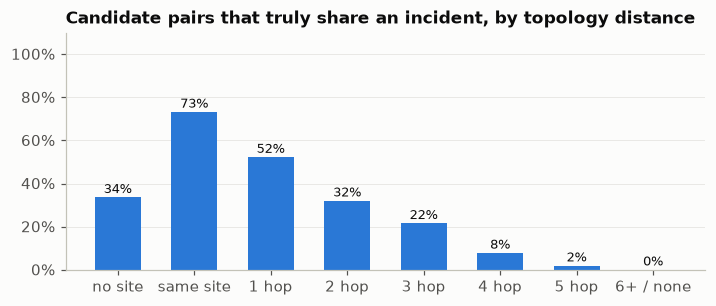

In [3]:
hop = np.concatenate([v["E"]["hop"] for v in days.values()])
same = np.concatenate([v["inc_id"][v["E"]["i"]] == v["inc_id"][v["E"]["j"]] for v in days.values()])
labels = {-1: "no site", 0: "same site", 9: "6+ / none"}
by_hop = pd.Series(same).groupby(hop).agg(["mean", "size"])
by_hop.index = [labels.get(h, f"{h} hop") for h in by_hop.index]

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.bar(by_hop.index, by_hop["mean"], color=BLUE, width=.6)
for x, (m_, n_) in enumerate(zip(by_hop["mean"], by_hop["size"])):
    ax.text(x, m_ + .02, f"{m_:.0%}", ha="center", color=INK, fontsize=8.5)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.1)
ax.set_title("Candidate pairs that truly share an incident, by topology distance")
ax.grid(axis="x", visible=False)
plt.show()

## 2 · The pair model

Each alarm is a node (alarm name, domain, severity, whether it has a site, hour of day). Each candidate pair carries 19
features: seconds apart, km apart, same site / device / domain / name, topology hops, and why it is a candidate. Two
GATv2 layers pass messages along the candidate pairs, so an alarm's vector reflects what is happening around it. A
symmetric head then scores each pair.

The model never sees clear times (the label), tickets (what we predict), or raw coordinates (it would learn regions).

Training used the clear-time labels of notebook 01. Below, the scores are judged against the **true** incidents of the
test days, which the model never saw.

Test pairs: ROC AUC 0.758, average precision 0.634 (base rate 34%)


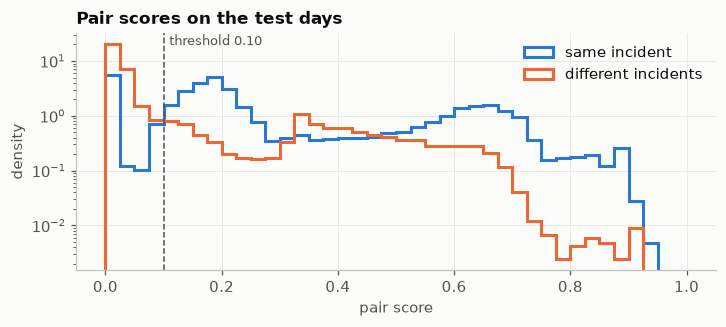

In [4]:
s_all = np.concatenate([v["s"] for v in days.values()])
auc, ap = roc_auc_score(same, s_all), average_precision_score(same, s_all)
print(f"Test pairs: ROC AUC {auc:.3f}, average precision {ap:.3f} (base rate {same.mean():.0%})")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
bins = np.linspace(0, 1, 41)
ax.hist(s_all[same], bins=bins, histtype="step", lw=2, color=BLUE, label="same incident", density=True)
ax.hist(s_all[~same], bins=bins, histtype="step", lw=2, color=ORANGE, label="different incidents", density=True)
ax.axvline(THR, color=MUTED, lw=1, ls="--")
ax.text(THR + .01, ax.get_ylim()[1] * .9, f"threshold {THR:.2f}", color=MUTED, fontsize=8.5)
ax.set_yscale("log")
ax.set_xlabel("pair score")
ax.set_ylabel("density")
ax.set_title("Pair scores on the test days")
ax.legend(loc="upper right")
plt.show()

## 3 · From scores to incidents

Scores are only half the job. The obvious next step, linking every pair above the threshold and taking connected pieces
(single linkage), **chains**: one strong pair joins two groups of any size, and on a busy day the pieces snowball.

Average linkage merges two groups only when the **mean** score over all pairs between them clears the threshold and
they are each other's best match. Tickets then join clusters by the same average, and each ticket ends in exactly one
incident.

The business measure is ticket pairs: of the tickets the method puts together, how many truly belong together
(precision), and of the tickets that truly belong together, how many it finds (recall).

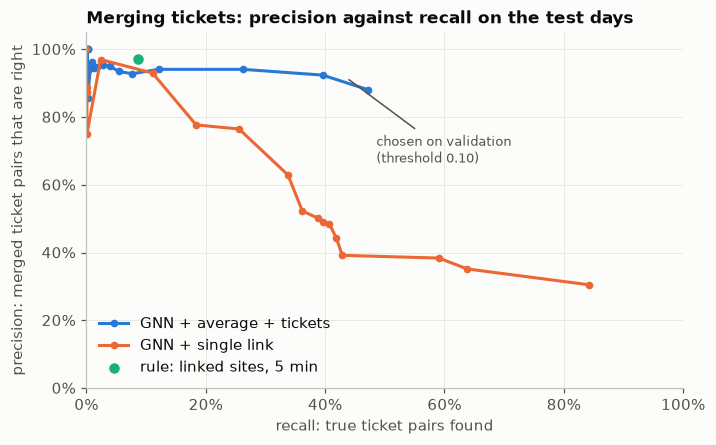

,largest group,ARI,B-cubed F1,ticket pairs merged,ticket-pair precision,ticket-pair recall
method,,,,,,
each alarm alone,1.00,0.000,0.699,0.00,NaN,0.000
"rule: linked sites, 5 min",41.25,0.151,0.704,178.75,0.973,0.086
GNN + single link,709.25,0.092,0.558,3654.50,0.397,0.668
GNN + average linkage,79.75,0.444,0.704,786.50,0.924,0.383
GNN + average + tickets,83.50,0.487,0.707,865.00,0.916,0.436


In [5]:
curve = pd.read_csv(RUN / "test_curve.csv")
results = pd.read_csv(RUN / "results.csv", index_col="method")

fig, ax = plt.subplots(figsize=(7, 4.2))
for method, colour in [("GNN + average + tickets", BLUE), ("GNN + single link", ORANGE)]:
    d = curve[curve.method == method].dropna(subset=["pair_precision"])
    ax.plot(d.pair_recall, d.pair_precision, color=colour, marker="o", ms=4, label=method)
rule = results.loc["rule: linked sites, 5 min"]
ax.scatter([rule.pair_recall], [rule.pair_precision], s=70, color=AQUA, zorder=3, edgecolor="#fcfcfb", lw=1.5,
           label="rule: linked sites, 5 min")
pick = results.loc["GNN + average + tickets"]
ax.annotate(f"chosen on validation\n(threshold {THR:.2f})", (pick.pair_recall, pick.pair_precision),
            xytext=(pick.pair_recall + .05, pick.pair_precision - .25), color=MUTED, fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_xlabel("recall: true ticket pairs found")
ax.set_ylabel("precision: merged ticket pairs that are right")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_title("Merging tickets: precision against recall on the test days")
ax.legend(loc="lower left")
fig.savefig(FIG / "ticket_pair_tradeoff.png", dpi=110, bbox_inches="tight")
plt.show()

cols = {"largest": "largest group", "ari": "ARI", "b3_f1": "B-cubed F1", "merged_pairs": "ticket pairs merged",
        "pair_precision": "ticket-pair precision", "pair_recall": "ticket-pair recall"}
results[list(cols)].rename(columns=cols).round(3)

### A case: what single linkage glues together

The largest single-link piece on the test days, drawn as alarms by onset time and site. On the left, coloured by the
true incident kind; on the right, by the groups that average linkage + tickets makes of the same alarms. The staircase on
the left is the chain at work: background alarms at neighbouring sites, each pair plausible on its own, link hour after
hour into one piece that also swallows the real faults it passes.

2026-01-18: single linkage joins 877 alarms from 286 true incidents (noise 275, radio_wave 3, site_power 2, hw_fault 2, fiber_cut 2, x2_storm 1, area_power 1).
Average linkage + tickets splits the same alarms into 169 groups.


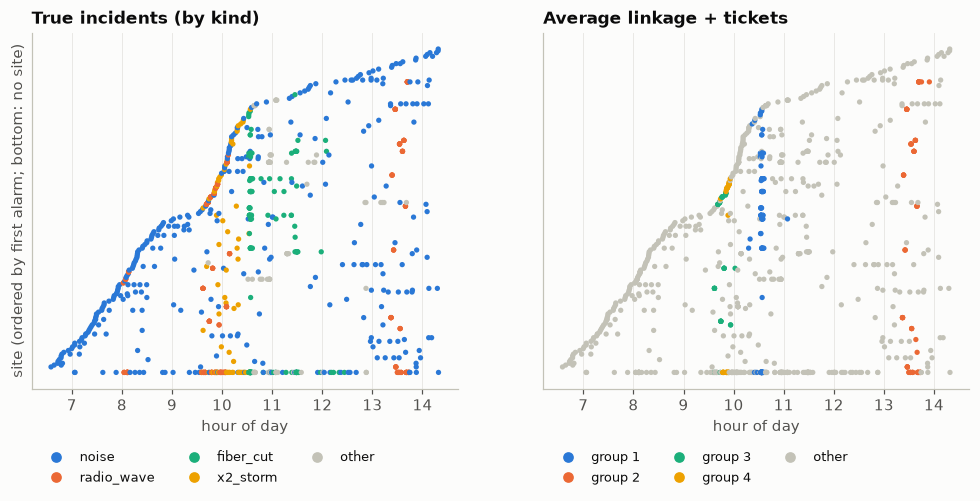

,alarms,true_incidents,main_kind,purity
group,,,,
601,118,2,fiber_cut,0.89
772,72,4,radio_wave,0.94
562,38,4,radio_wave,0.89
569,38,2,radio_wave,0.68
576,35,2,radio_wave,0.63
682,29,3,fiber_cut,0.93
469,22,1,radio_wave,1.00
755,21,10,noise,0.19


In [6]:
best = None
for d, v in days.items():
    sl = cluster.single_link(len(v["n"]), v["E"]["i"], v["E"]["j"], v["s"], THR)
    size = np.bincount(sl)
    if best is None or size.max() > best[2]:
        best = (d, sl, int(size.max()), int(size.argmax()))
d, sl, size, big = best
v = days[d]
_, inc = group_day(len(v["n"]), v["E"], v["s"], v["nt"], THR)
m = sl == big
comp = pd.DataFrame({"hour": v["n"].t.to_numpy()[m] / 3600, "site": v["n"].site.to_numpy()[m],
                     "incident": v["inc_id"][m], "group": inc[m]})
comp["kind"] = comp.incident.map(kind_of)
print(f"{d.date()}: single linkage joins {size} alarms from {comp.incident.nunique()} true incidents "
      f"({', '.join(f'{k} {n}' for k, n in comp.drop_duplicates('incident').kind.value_counts().items())}).")
print(f"Average linkage + tickets splits the same alarms into {comp.group.nunique()} groups.")

order = comp[comp.site != ""].groupby("site").hour.min().sort_values()
comp["y"] = comp.site.map({s: k for k, s in enumerate(order.index)}).fillna(-3)

def colours(series, top=4):
    lead = series.value_counts().index[:top]
    pal = dict(zip(lead, [BLUE, ORANGE, AQUA, YELLOW]))
    return series.map(lambda x: pal.get(x, OTHER)), pal

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, title in [(axes[0], "kind", "True incidents (by kind)"), (axes[1], "group", "Average linkage + tickets")]:
    col_s, pal = colours(comp[col])
    ax.scatter(comp.hour, comp.y, s=12, c=col_s, edgecolor="none")
    handles = [plt.Line2D([], [], marker="o", ls="", color=cc, label=(str(k) if col == "kind" else f"group {i + 1}"))
               for i, (k, cc) in enumerate(pal.items())]
    handles.append(plt.Line2D([], [], marker="o", ls="", color=OTHER, label="other"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -.14), ncol=3, fontsize=8.5)
    ax.set_title(title)
    ax.set_xlabel("hour of day")
axes[0].set_ylabel("site (ordered by first alarm; bottom: no site)")
axes[0].set_yticks([])
fig.savefig(FIG / "case_single_vs_average.png", dpi=110, bbox_inches="tight")
plt.show()

comp.groupby("group").agg(alarms=("incident", "size"), true_incidents=("incident", "nunique"),
                          main_kind=("kind", lambda s: s.value_counts().index[0]),
                          purity=("incident", lambda s: round(s.value_counts().iloc[0] / len(s), 2))
                          ).sort_values("alarms", ascending=False).head(8)

## 4 · Where it still fails

Ticket-pair recall by the kind of incident the two tickets truly share, and the kinds of the wrong merges.

264 wrong merges; the kinds they glue together:


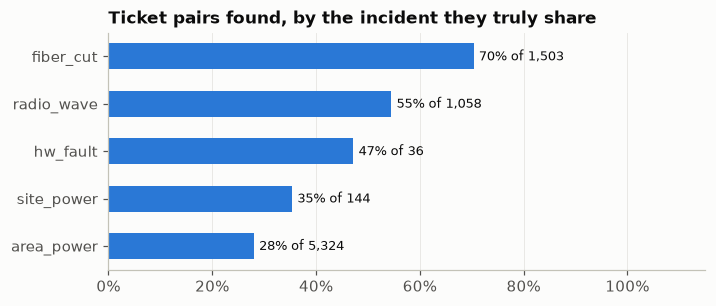

,wrong merges
hw_fault + radio_wave,77
area_power + radio_wave,38
area_power + site_power,34
site_power + site_power,29
area_power + noise,18
area_power + area_power,18
area_power + fiber_cut,14
hw_fault + hw_fault,11


In [7]:
found, wrong = [], []
for v in days.values():
    _, inc = group_day(len(v["n"]), v["E"], v["s"], v["nt"], THR)
    hp, ht = ticket_homes(inc, v["nt"]), ticket_homes(v["true"], v["nt"])
    t_inc = pd.Series(v["uniq"][ht.to_numpy()], index=ht.index)
    t_kind = t_inc.map(kind_of)
    for _, members in t_inc.groupby(t_inc).groups.items():
        found += [(t_kind[a], hp[a] == hp[b]) for a, b in combinations(members, 2)]
    for _, members in hp.groupby(hp).groups.items():
        wrong += [" + ".join(sorted((t_kind[a], t_kind[b]))) for a, b in combinations(members, 2) if t_inc[a] != t_inc[b]]
found = pd.DataFrame(found, columns=["kind", "merged"])
by_kind = found.groupby("kind").merged.agg(pairs="size", recall="mean").sort_values("recall")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(by_kind.index, by_kind.recall, color=BLUE, height=.55)
for y, (r_, n_) in enumerate(zip(by_kind.recall, by_kind.pairs)):
    ax.text(r_ + .01, y, f"{r_:.0%} of {n_:,}", va="center", color=INK, fontsize=8.5)
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Ticket pairs found, by the incident they truly share")
ax.grid(axis="y", visible=False)
plt.show()

print(f"{len(wrong)} wrong merges; the kinds they glue together:")
pd.Series(wrong).value_counts().rename("wrong merges").head(8).to_frame()

## Takeaways

* **Clustering matters as much as the model.** On the same scores, single linkage trades away precision for recall and
  builds giant groups; average linkage keeps precision high at every recall level it reaches.
* **The threshold was picked without ground truth**, from resolution codes on the validation days, and it lands at a
  sensible point of the test curve.
* **Large, fast events are found; slow ones are not.** Kinds whose alarms arrive over hours (crews restoring sites one by
  one, batteries draining at different rates) are where recall is lost, and incidents that overlap in time and place are
  where the wrong merges come from.
* These are synthetic numbers. They show the method's behaviour, not production performance.